## Logs and epochs

In [2]:
!ls logs

root_stream_bim_2_shuffle_false_epochs_10_20261110_061713
root_stream_bim_2_shuffle_false_epochs_1_20261110_025522
root_stream_bim_2_shuffle_false_epochs_50_20261110_025958


### Log exploration

In [3]:
import json
from pprint import pprint
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import matplotlib.colors as mcolors
from matplotlib.cm import ScalarMappable

In [4]:
FILE_E1 = 'logs/root_stream_bim_2_shuffle_false_epochs_1_20261110_025522/darshan_logs/strategy_stream_bim_2_shuffle_false_batchsize_64_epochs_1/satt_python3_id1749126-1749126_11-10-10523-5712789554778768917_1.darshan.json'
FILE_E2 = 'logs/root_stream_bim_2_shuffle_false_epochs_10_20261110_061713/darshan_logs/strategy_stream_bim_2_shuffle_false_batchsize_64_epochs_10/satt_python3_id1268171-1268171_11-10-22634-15246891861428475467_1.darshan.json'
FILE_E3 = 'logs/root_stream_bim_2_shuffle_false_epochs_50_20261110_025958/darshan_logs/strategy_stream_bim_2_shuffle_false_batchsize_64_epochs_50/satt_python3_id292472-292472_11-10-10799-13227730035649892144_1.darshan.json'

In [5]:
with open(FILE_E2) as file_e2:
    d = json.load(file_e2)
    file_e2.close()
pprint(d)

{'counters': {'DXT_POSIX': {},
              'POSIX': {'counters': ['POSIX_OPENS',
                                     'POSIX_FILENOS',
                                     'POSIX_DUPS',
                                     'POSIX_READS',
                                     'POSIX_WRITES',
                                     'POSIX_SEEKS',
                                     'POSIX_STATS',
                                     'POSIX_MMAPS',
                                     'POSIX_FSYNCS',
                                     'POSIX_FDSYNCS',
                                     'POSIX_RENAME_SOURCES',
                                     'POSIX_RENAME_TARGETS',
                                     'POSIX_RENAMED_FROM',
                                     'POSIX_MODE',
                                     'POSIX_BYTES_READ',
                                     'POSIX_BYTES_WRITTEN',
                                     'POSIX_MAX_BYTE_READ',
                                   

In [6]:
len(d['name_records'])

4160

In [7]:
name_records_raw = d['name_records']
name_records = name_records_raw.items()
name_records_list = list(name_records)
for i in range(10):
    print(name_records_list[i])

('16592106915301738621', 'heatmap:POSIX')
('14734109647742566553', '<STDIN>')
('15920181672442173319', '<STDOUT>')
('7238257241479193519', '<STDERR>')
('3989511027826779520', 'heatmap:STDIO')
('1183378753704768064', '/pscratch/sd/s/satt/sprints/myvenv/pyvenv.cfg')
('2753586021477318973', '/global/common/software/nersc/pe/conda-envs/26.8.0/python-3.13/nersc-python/lib/python3.13/os.py')
('14915634845633470549', '/global/common/software/nersc/pe/conda-envs/26.8.0/python-3.13/nersc-python/lib/python3.13/encodings/__init__.py')
('1279809238936159499', '/global/common/software/nersc/pe/conda-envs/26.8.0/python-3.13/nersc-python/lib/python3.13/encodings/aliases.py')
('14471277080580643569', '/global/common/software/nersc/pe/conda-envs/26.8.0/python-3.13/nersc-python/lib/python3.13/encodings/utf_8.py')


In [8]:
key_roots = [key for key, val in name_records if '9.root' in val]
key_roots

['2684797316911919626']

In [9]:
for i in key_roots:
    print(name_records_raw[i])

/pscratch/sd/s/satt/sprints/data/roots/mc_normalized_rntuple_10M_9.root


In [10]:
key_py = [key for key, val in name_records if '9.py' in val]
key_py 

['5375169344426660457', '1352634379817058008']

In [11]:
for i in key_py:
    print(name_records_raw[i])

/pscratch/sd/s/satt/sprints/a_star_campaign/root/root_tr_9.py
/pscratch/sd/s/satt/sprints/myvenv/lib/python3.13/site-packages/torch/onnx/_internal/torchscript_exporter/symbolic_opset9.py


In [12]:
DXT_POSIX_recs = d['records']['DXT_POSIX']
STDIO_recs = d['records']['STDIO']
POSIX_recs = d['records']['POSIX']

In [13]:
rows_from_POSIX = []
for i in POSIX_recs:
    ide = str(i['id'])
    if ide in key_py or ide in key_roots:
        print(i)
        rows_from_POSIX.append(i)

{'id': 5375169344426660457, 'rank': 0, 'counters': [5, 3, 0, 10, 0, 13, 19, -1, 0, 0, 0, 0, 0, 0, 209394, 0, 105375, 0, 5, 0, 5, 0, 0, 1, 8, 5, 1048576, 105376, 0, 5, 0, 0, 4, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 26953, 105376, 27480, 22632, 2, 1, 1, 1, 0, 0, 0, 0], 'fcounters': [0.19697356224060059, 0.19722342491149902, 0.0, 0.19774866104125977, 4.714336633682251, 4.714490652084351, 0.0, 4.71450662612915, 0.0031404495239257812, 0.0, 0.001934051513671875, 0.0012731552124023438, 0.0, 0.0, 0.0, 0.0, 0.0]}
{'id': 2684797316911919626, 'rank': 0, 'counters': [3, 0, 0, 205, 0, 5, 4, -1, 0, 0, 0, 0, 0, 0, 12525040407, 0, 1250866430, 0, 9, 0, 185, 0, 0, 86, 8, 202, 1048576, 198846222, 0, 8, 11, 0, 2, 0, 4, 80, 20, 80, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 42, 5303, 3780, 3775, 80, 10, 10, 10, 198846222, 127582302, 127395779, 127245188, 10, 10, 10, 10, 0, 0, 0, 0], 'fcounters': [14.92555046081543, 14.925748109817505, 0.0, 14.947654962539673, 21.105403184890747, 207

In [14]:
POSIX_counters = d['counters']['POSIX']['counters']
POSIX_counters

['POSIX_OPENS',
 'POSIX_FILENOS',
 'POSIX_DUPS',
 'POSIX_READS',
 'POSIX_WRITES',
 'POSIX_SEEKS',
 'POSIX_STATS',
 'POSIX_MMAPS',
 'POSIX_FSYNCS',
 'POSIX_FDSYNCS',
 'POSIX_RENAME_SOURCES',
 'POSIX_RENAME_TARGETS',
 'POSIX_RENAMED_FROM',
 'POSIX_MODE',
 'POSIX_BYTES_READ',
 'POSIX_BYTES_WRITTEN',
 'POSIX_MAX_BYTE_READ',
 'POSIX_MAX_BYTE_WRITTEN',
 'POSIX_CONSEC_READS',
 'POSIX_CONSEC_WRITES',
 'POSIX_SEQ_READS',
 'POSIX_SEQ_WRITES',
 'POSIX_RW_SWITCHES',
 'POSIX_MEM_NOT_ALIGNED',
 'POSIX_MEM_ALIGNMENT',
 'POSIX_FILE_NOT_ALIGNED',
 'POSIX_FILE_ALIGNMENT',
 'POSIX_MAX_READ_TIME_SIZE',
 'POSIX_MAX_WRITE_TIME_SIZE',
 'POSIX_SIZE_READ_0_100',
 'POSIX_SIZE_READ_100_1K',
 'POSIX_SIZE_READ_1K_10K',
 'POSIX_SIZE_READ_10K_100K',
 'POSIX_SIZE_READ_100K_1M',
 'POSIX_SIZE_READ_1M_4M',
 'POSIX_SIZE_READ_4M_10M',
 'POSIX_SIZE_READ_10M_100M',
 'POSIX_SIZE_READ_100M_1G',
 'POSIX_SIZE_READ_1G_PLUS',
 'POSIX_SIZE_WRITE_0_100',
 'POSIX_SIZE_WRITE_100_1K',
 'POSIX_SIZE_WRITE_1K_10K',
 'POSIX_SIZE_WRITE_10K

In [15]:
POSIX_fcounters = d['counters']['POSIX']['fcounters']
POSIX_fcounters

['POSIX_F_OPEN_START_TIMESTAMP',
 'POSIX_F_READ_START_TIMESTAMP',
 'POSIX_F_WRITE_START_TIMESTAMP',
 'POSIX_F_CLOSE_START_TIMESTAMP',
 'POSIX_F_OPEN_END_TIMESTAMP',
 'POSIX_F_READ_END_TIMESTAMP',
 'POSIX_F_WRITE_END_TIMESTAMP',
 'POSIX_F_CLOSE_END_TIMESTAMP',
 'POSIX_F_READ_TIME',
 'POSIX_F_WRITE_TIME',
 'POSIX_F_META_TIME',
 'POSIX_F_MAX_READ_TIME',
 'POSIX_F_MAX_WRITE_TIME',
 'POSIX_F_FASTEST_RANK_TIME',
 'POSIX_F_SLOWEST_RANK_TIME',
 'POSIX_F_VARIANCE_RANK_TIME',
 'POSIX_F_VARIANCE_RANK_BYTES']

In [16]:
len(rows_from_POSIX[0]['counters']) == len(POSIX_counters)

True

In [17]:
cross_counters_0 = dict(zip(POSIX_counters, rows_from_POSIX[0]['counters']))
pprint(cross_counters_0)

{'POSIX_ACCESS1_ACCESS': 26953,
 'POSIX_ACCESS1_COUNT': 2,
 'POSIX_ACCESS2_ACCESS': 105376,
 'POSIX_ACCESS2_COUNT': 1,
 'POSIX_ACCESS3_ACCESS': 27480,
 'POSIX_ACCESS3_COUNT': 1,
 'POSIX_ACCESS4_ACCESS': 22632,
 'POSIX_ACCESS4_COUNT': 1,
 'POSIX_BYTES_READ': 209394,
 'POSIX_BYTES_WRITTEN': 0,
 'POSIX_CONSEC_READS': 5,
 'POSIX_CONSEC_WRITES': 0,
 'POSIX_DUPS': 0,
 'POSIX_FASTEST_RANK': 0,
 'POSIX_FASTEST_RANK_BYTES': 0,
 'POSIX_FDSYNCS': 0,
 'POSIX_FILENOS': 3,
 'POSIX_FILE_ALIGNMENT': 1048576,
 'POSIX_FILE_NOT_ALIGNED': 5,
 'POSIX_FSYNCS': 0,
 'POSIX_MAX_BYTE_READ': 105375,
 'POSIX_MAX_BYTE_WRITTEN': 0,
 'POSIX_MAX_READ_TIME_SIZE': 105376,
 'POSIX_MAX_WRITE_TIME_SIZE': 0,
 'POSIX_MEM_ALIGNMENT': 8,
 'POSIX_MEM_NOT_ALIGNED': 1,
 'POSIX_MMAPS': -1,
 'POSIX_MODE': 0,
 'POSIX_OPENS': 5,
 'POSIX_READS': 10,
 'POSIX_RENAMED_FROM': 0,
 'POSIX_RENAME_SOURCES': 0,
 'POSIX_RENAME_TARGETS': 0,
 'POSIX_RW_SWITCHES': 0,
 'POSIX_SEEKS': 13,
 'POSIX_SEQ_READS': 5,
 'POSIX_SEQ_WRITES': 0,
 'POSIX_SIZE_

In [18]:
cross_counters_1 = dict(zip(POSIX_counters, rows_from_POSIX[1]['counters']))
pprint(cross_counters_1)

{'POSIX_ACCESS1_ACCESS': 198846222,
 'POSIX_ACCESS1_COUNT': 10,
 'POSIX_ACCESS2_ACCESS': 127582302,
 'POSIX_ACCESS2_COUNT': 10,
 'POSIX_ACCESS3_ACCESS': 127395779,
 'POSIX_ACCESS3_COUNT': 10,
 'POSIX_ACCESS4_ACCESS': 127245188,
 'POSIX_ACCESS4_COUNT': 10,
 'POSIX_BYTES_READ': 12525040407,
 'POSIX_BYTES_WRITTEN': 0,
 'POSIX_CONSEC_READS': 9,
 'POSIX_CONSEC_WRITES': 0,
 'POSIX_DUPS': 0,
 'POSIX_FASTEST_RANK': 0,
 'POSIX_FASTEST_RANK_BYTES': 0,
 'POSIX_FDSYNCS': 0,
 'POSIX_FILENOS': 0,
 'POSIX_FILE_ALIGNMENT': 1048576,
 'POSIX_FILE_NOT_ALIGNED': 202,
 'POSIX_FSYNCS': 0,
 'POSIX_MAX_BYTE_READ': 1250866430,
 'POSIX_MAX_BYTE_WRITTEN': 0,
 'POSIX_MAX_READ_TIME_SIZE': 198846222,
 'POSIX_MAX_WRITE_TIME_SIZE': 0,
 'POSIX_MEM_ALIGNMENT': 8,
 'POSIX_MEM_NOT_ALIGNED': 86,
 'POSIX_MMAPS': -1,
 'POSIX_MODE': 0,
 'POSIX_OPENS': 3,
 'POSIX_READS': 205,
 'POSIX_RENAMED_FROM': 0,
 'POSIX_RENAME_SOURCES': 0,
 'POSIX_RENAME_TARGETS': 0,
 'POSIX_RW_SWITCHES': 0,
 'POSIX_SEEKS': 5,
 'POSIX_SEQ_READS': 185,
 

In [19]:
cross_fcounters_0 = dict(zip(POSIX_fcounters, rows_from_POSIX[0]['fcounters']))
pprint(cross_fcounters_0)

{'POSIX_F_CLOSE_END_TIMESTAMP': 4.71450662612915,
 'POSIX_F_CLOSE_START_TIMESTAMP': 0.19774866104125977,
 'POSIX_F_FASTEST_RANK_TIME': 0.0,
 'POSIX_F_MAX_READ_TIME': 0.0012731552124023438,
 'POSIX_F_MAX_WRITE_TIME': 0.0,
 'POSIX_F_META_TIME': 0.001934051513671875,
 'POSIX_F_OPEN_END_TIMESTAMP': 4.714336633682251,
 'POSIX_F_OPEN_START_TIMESTAMP': 0.19697356224060059,
 'POSIX_F_READ_END_TIMESTAMP': 4.714490652084351,
 'POSIX_F_READ_START_TIMESTAMP': 0.19722342491149902,
 'POSIX_F_READ_TIME': 0.0031404495239257812,
 'POSIX_F_SLOWEST_RANK_TIME': 0.0,
 'POSIX_F_VARIANCE_RANK_BYTES': 0.0,
 'POSIX_F_VARIANCE_RANK_TIME': 0.0,
 'POSIX_F_WRITE_END_TIMESTAMP': 0.0,
 'POSIX_F_WRITE_START_TIMESTAMP': 0.0,
 'POSIX_F_WRITE_TIME': 0.0}


In [20]:
cross_fcounters_1 = dict(zip(POSIX_fcounters, rows_from_POSIX[1]['fcounters']))
pprint(cross_fcounters_1)

{'POSIX_F_CLOSE_END_TIMESTAMP': 2111.8522686958313,
 'POSIX_F_CLOSE_START_TIMESTAMP': 14.947654962539673,
 'POSIX_F_FASTEST_RANK_TIME': 0.0,
 'POSIX_F_MAX_READ_TIME': 0.1650080680847168,
 'POSIX_F_MAX_WRITE_TIME': 0.0,
 'POSIX_F_META_TIME': 0.0005714893341064453,
 'POSIX_F_OPEN_END_TIMESTAMP': 21.105403184890747,
 'POSIX_F_OPEN_START_TIMESTAMP': 14.92555046081543,
 'POSIX_F_READ_END_TIMESTAMP': 2072.623165369034,
 'POSIX_F_READ_START_TIMESTAMP': 14.925748109817505,
 'POSIX_F_READ_TIME': 3.126365900039673,
 'POSIX_F_SLOWEST_RANK_TIME': 0.0,
 'POSIX_F_VARIANCE_RANK_BYTES': 0.0,
 'POSIX_F_VARIANCE_RANK_TIME': 0.0,
 'POSIX_F_WRITE_END_TIMESTAMP': 0.0,
 'POSIX_F_WRITE_START_TIMESTAMP': 0.0,
 'POSIX_F_WRITE_TIME': 0.0}


### Chronological reconstruction

In [21]:
DXT_TRACE_PATH = 'logs/root_stream_bim_2_shuffle_false_epochs_10_20261110_061713/darshan_logs/strategy_stream_bim_2_shuffle_false_batchsize_64_epochs_10/satt_python3_id1268171-1268171_11-10-22634-15246891861428475467_1.darshan.dxt.txt'

In [22]:
with open(DXT_TRACE_PATH) as trace:
    content = trace.read()
print(content)

# darshan log version: 3.41
# compression method: ZLIB
# exe: /pscratch/sd/s/satt/sprints/myvenv/bin/python3 /pscratch/sd/s/satt/sprints/a_star_campaign/root/root_tr_9.py --data-path /pscratch/sd/s/satt/sprints/data/roots/mc_normalized_rntuple_10M_9.root --tree-name tree --target-col Label --strategy stream --no-shuffle --model M2 --batch-size 64 --epochs 10 --log-every 50000 
# uid: 114163
# jobid: 1268171
# start_time: 1794320234
# start_time_asci: Tue Nov 10 09:17:14 2026
# end_time: 1794322347
# end_time_asci: Tue Nov 10 09:52:27 2026
# nprocs: 1
# run time: 2113.0021
# metadata: lib_ver = 3.5.0

# log file regions
# -------------------------------------------------------
# header: 1328 bytes (uncompressed)
# job data: 758 bytes (compressed)
# record table: 73722 bytes (compressed)
# POSIX module: 85778 bytes (compressed), ver=4
# STDIO module: 1895 bytes (compressed), ver=2
# DXT_POSIX module: 10893 bytes (compressed), ver=2
# HEATMAP module: 262 bytes (compressed), ver=1

# mount

In [23]:
keys_all = []
keys_all.append([key_roots, key_py])

In [24]:
keys_all = sum(sum(keys_all, []),[])
keys_all

['2684797316911919626', '5375169344426660457', '1352634379817058008']

In [25]:
dxt_section = content.split("# DXT_POSIX module data")[1]
print(dxt_section)


# ***************************************************

# DXT, file_id: 1183378753704768064, file_name: /pscratch/sd/s/satt/sprints/myvenv/pyvenv.cfg
# DXT, rank: 0, hostname: nid004701
# DXT, number of threads: 1
# DXT, write_count: 0, read_count: 4
# DXT, mnt_pt: /pscratch, fs_type: lustre
# Module    Rank  Wt/Rd  Segment          Offset          Length    Start(s)      End(s)   Pthread-ID
 X_POSIX       0   read        0               0            6339      0.0296      0.0305   140677929441088
 X_POSIX       0   read        1            6339               0      0.0306      0.0306   140677929441088
 X_POSIX       0   read        2               0             387      0.0389      0.0389   140677929441088
 X_POSIX       0   read        3             387               0      0.0389      0.0389   140677929441088

# DXT, file_id: 6509654755798325290, file_name: /pscratch/sd/s/satt/sprints/myvenv/lib/python3.13/site-packages/distutils-precedence.pth
# DXT, rank: 0, hostname: nid004701
# D

In [26]:
blocks = re.split(
    r"(?=^# DXT, file_id:)",
    dxt_section,
    flags=re.MULTILINE
)

In [27]:
selected = []
for block in blocks:
    match = re.match(r"# DXT, file_id:\s*(\d+)", block.lstrip())

    if match and match.group(1) in {str(k) for k in keys_all}:
        selected.append(block.strip())
print(selected)

['# DXT, file_id: 5375169344426660457, file_name: /pscratch/sd/s/satt/sprints/a_star_campaign/root/root_tr_9.py\n# DXT, rank: 0, hostname: nid004701\n# DXT, number of threads: 1\n# DXT, write_count: 0, read_count: 10\n# DXT, mnt_pt: /pscratch, fs_type: lustre\n# Module    Rank  Wt/Rd  Segment          Offset          Length    Start(s)      End(s)   Pthread-ID\n X_POSIX       0   read        0               0           26953      0.1972      0.1977   140677929441088\n X_POSIX       0   read        1           26953               0      0.1977      0.1977   140677929441088\n X_POSIX       0   read        2               0          105376      0.2030      0.2043   140677929441088\n X_POSIX       0   read        3          105376               0      0.2043      0.2043   140677929441088\n X_POSIX       0   read        4               0           22632      0.2057      0.2065   140677929441088\n X_POSIX       0   read        5           22632               0      0.2065      0.2065   14067

In [28]:
def parse_dxt_block(block):
    
    def extract(pattern):
        match = re.search(pattern, block, re.MULTILINE)
        if not match:
            raise ValueError(f"Missing field: {pattern}")
        return match.groups()
    
    file_id, file_name = extract(
        r"^# DXT, file_id:\s*(\d+), file_name:\s*(.+)$"
    )

    rank, hostname = extract(
        r"^# DXT, rank:\s*(-?\d+), hostname:\s*(.+)$"
    )

    (nthreads,) = extract(
        r"^# DXT, number of threads:\s*(\d+)$"
    )

    write_count, read_count = extract(
        r"^# DXT, write_count:\s*(\d+), read_count:\s*(\d+)$"
    )

    mnt_pt, fs_type = extract(
        r"^# DXT, mnt_pt:\s*(.*?), fs_type:\s*(.+)$"
    )

    rows = []

    for line in block.splitlines():
        cols = line.split()

        if not cols or cols[0] != "X_POSIX":
            continue
            
        if len(cols) != 9:
            raise ValueError(f"Invalid DXT row: {line}")
        
        module, row_rank, operation, segment, offset, length, start, end, pthread = cols

        rows.append({
            "module": module,
            "rank": int(row_rank),
            "operation": operation,
            "segment": int(segment),
            "offset": int(offset),
            "length": int(length),
            "start_s": float(start),
            "end_s": float(end),
            "pthread_id": None if pthread == "-1" else pthread
        })

    result = {
        "file_id": file_id,
        "file_name": file_name,
        "rank": int(rank),
        "hostname": hostname,
        "nthreads": int(nthreads),
        "write_count": int(write_count),
        "read_count": int(read_count),
        "mnt_pt": mnt_pt,
        "fs_type": fs_type,
        "rows": rows
    }

    return result

dxt_data = [parse_dxt_block(block) for block in selected]
        

In [29]:
dxt_data

[{'file_id': '5375169344426660457',
  'file_name': '/pscratch/sd/s/satt/sprints/a_star_campaign/root/root_tr_9.py',
  'rank': 0,
  'hostname': 'nid004701',
  'nthreads': 1,
  'write_count': 0,
  'read_count': 10,
  'mnt_pt': '/pscratch',
  'fs_type': 'lustre',
  'rows': [{'module': 'X_POSIX',
    'rank': 0,
    'operation': 'read',
    'segment': 0,
    'offset': 0,
    'length': 26953,
    'start_s': 0.1972,
    'end_s': 0.1977,
    'pthread_id': '140677929441088'},
   {'module': 'X_POSIX',
    'rank': 0,
    'operation': 'read',
    'segment': 1,
    'offset': 26953,
    'length': 0,
    'start_s': 0.1977,
    'end_s': 0.1977,
    'pthread_id': '140677929441088'},
   {'module': 'X_POSIX',
    'rank': 0,
    'operation': 'read',
    'segment': 2,
    'offset': 0,
    'length': 105376,
    'start_s': 0.203,
    'end_s': 0.2043,
    'pthread_id': '140677929441088'},
   {'module': 'X_POSIX',
    'rank': 0,
    'operation': 'read',
    'segment': 3,
    'offset': 105376,
    'length': 0,


In [30]:
with open("filtered_dxt_10.json", "w") as f:
    json.dump(dxt_data, f)

In [31]:
# Verify 
for record in dxt_data:
    reads = sum(
        row["operation"] == "read"
        for row in record["rows"]
    )

    writes = sum(
        row["operation"] == "write"
        for row in record["rows"]
    )

    assert reads == record["read_count"]
    assert writes == record["write_count"]

    print(record["file_name"])
    print(f"  Reads:  {reads}")
    print(f"  Writes: {writes}")
    print(f"  Threads: {record['nthreads']}")

/pscratch/sd/s/satt/sprints/a_star_campaign/root/root_tr_9.py
  Reads:  10
  Writes: 0
  Threads: 1
/pscratch/sd/s/satt/sprints/data/roots/mc_normalized_rntuple_10M_9.root
  Reads:  205
  Writes: 0
  Threads: 2


In [32]:
root_data = next(
    record for record in dxt_data
    if record["file_name"].endswith(
        ".root"
    )
)

df_root = pd.DataFrame(root_data["rows"])

df_root

,module,rank,operation,segment,offset,length,start_s,end_s,pthread_id
0,X_POSIX,0,read,0,0,300,14.9257,14.9265,140677929441088
1,X_POSIX,0,read,1,1250865843,125,14.9266,14.9269,140677929441088
2,X_POSIX,0,read,2,1250865968,386,14.9269,14.9269,140677929441088
3,X_POSIX,0,read,3,1250865711,132,14.9325,14.9325,140677929441088
4,X_POSIX,0,read,4,1250865711,132,14.9325,14.9325,140677929441088
...,...,...,...,...,...,...,...,...,...
200,X_POSIX,0,read,200,1009362339,7391620,2027.7482,2027.7497,140671271515840
201,X_POSIX,0,read,201,1016754001,126934917,2050.1646,2050.1844,140671271515840
202,X_POSIX,0,read,202,1143691866,7390699,2050.1844,2050.1854,140671271515840
203,X_POSIX,0,read,203,1151082607,94289937,2072.6078,2072.6220,140671271515840


In [33]:
py_data = next(
    record for record in dxt_data
    if record["file_name"].endswith(
        ".py"
    )
)

df_py = pd.DataFrame(py_data["rows"])

df_py

,module,rank,operation,segment,offset,length,start_s,end_s,pthread_id
0,X_POSIX,0,read,0,0,26953,0.1972,0.1977,140677929441088
1,X_POSIX,0,read,1,26953,0,0.1977,0.1977,140677929441088
2,X_POSIX,0,read,2,0,105376,0.2030,0.2043,140677929441088
3,X_POSIX,0,read,3,105376,0,0.2043,0.2043,140677929441088
4,X_POSIX,0,read,4,0,22632,0.2057,0.2065,140677929441088
5,X_POSIX,0,read,5,22632,0,0.2065,0.2065,140677929441088
6,X_POSIX,0,read,6,0,27480,0.2091,0.2096,140677929441088
7,X_POSIX,0,read,7,27480,0,0.2096,0.2096,140677929441088
8,X_POSIX,0,read,8,0,26953,4.7144,4.7144,140677929441088
9,X_POSIX,0,read,9,26953,0,4.7145,4.7145,140677929441088


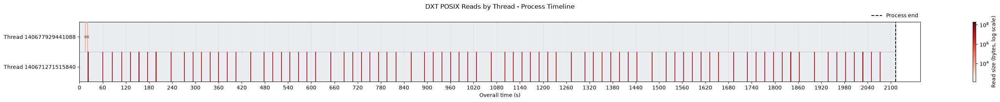

In [34]:
runtime = d["metadata"]["job"]["run_time"]

dataset_record = next(
    record for record in dxt_data
    if record["file_name"].endswith(".root")
)

reads = sorted(
    [row for row in dataset_record["rows"]
     if row["operation"] == "read"],
    key=lambda row: row["start_s"]
)

positive_lengths = [r["length"] for r in reads if r["length"] > 0]

norm = mcolors.LogNorm(
    vmin=min(positive_lengths),
    vmax=max(positive_lengths)
)

cmap = plt.get_cmap("Reds")

# Group reads by thread
thread_ids = sorted({str(r["pthread_id"]) for r in reads})
thread_reads = {
    tid: [r for r in reads if str(r["pthread_id"]) == tid]
    for tid in thread_ids
}

fig, ax = plt.subplots(figsize=(30, 2.8))

lane_height = 0.8

# Contiguous thread lanes
lane_bottoms = {
    tid: i * lane_height
    for i, tid in enumerate(thread_ids)
}

for tid in thread_ids:
    y0 = lane_bottoms[tid]

    # Full process duration background
    ax.broken_barh(
        [(0, runtime)],
        (y0, lane_height),
        facecolors="#ebedf0",
        edgecolors="#c8ccd1",
        zorder=1
    )

    # Read intervals
    for row in thread_reads[tid]:
        start = row["start_s"]
        end = row["end_s"]
        length = row["length"]
        duration = end - start

        if length == 0:
            ax.plot(
                start,
                y0 + lane_height / 2,
                "x",
                color="gray",
                markersize=5,
                zorder=5
            )
            continue

        color = cmap(norm(length))

        if duration > 0:
            ax.broken_barh(
                [(start, duration)],
                (y0, lane_height),
                facecolors=color,
                edgecolors="none",
                zorder=3
            )

        # Start marker for visibility
        ax.vlines(
            start,
            y0,
            y0 + lane_height,
            color=color,
            linewidth=1.2,
            zorder=4
        )

# Process end marker
ax.axvline(
    runtime,
    color="black",
    linestyle="--",
    label="Process end",
    zorder=6
)

ax.set_xlim(0, runtime * 1.03)
ax.set_ylim(0, lane_height * len(thread_ids))

# X-axis ticks every 5 seconds
ax.set_xticks(range(0, int(runtime) + 1, 60))

# Actual thread IDs
ax.set_yticks([
    lane_bottoms[tid] + lane_height / 2
    for tid in thread_ids
])
ax.set_yticklabels([
    f"Thread {tid}"
    for tid in thread_ids
])

ax.set_xlabel("Overall time (s)")
ax.set_title(
    "DXT POSIX Reads by Thread - Process Timeline",
    pad=25
)

ax.grid(axis="x", alpha=0.2)

# Logarithmic read-size colorbar
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("Read size (bytes, log scale)")

# Legend outside the plotting area
ax.legend(
    loc="lower right",
    bbox_to_anchor=(1, 1.02),
    frameon=False,
    borderaxespad=0
)

plt.tight_layout()
plt.savefig(
    "dxt_two_thread_timeline_contiguous_root10.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

Selected application events: 76
   13.876s  main_start
   13.885s  train_start
   18.650s  loader_build_start
   18.650s  loader_build_end
   18.650s  epoch_start
   23.765s  first_batch_received
   24.111s  first_batch_processed
   94.900s  batch_checkpoint
  163.205s  batch_checkpoint
  228.831s  batch_checkpoint
  236.818s  epoch_end
  236.818s  epoch_start
  237.864s  first_batch_received
  237.867s  first_batch_processed
  303.251s  batch_checkpoint
  369.439s  batch_checkpoint
  435.595s  batch_checkpoint
  443.555s  epoch_end
  443.555s  epoch_start
  444.607s  first_batch_received
  444.609s  first_batch_processed
  509.811s  batch_checkpoint
  576.033s  batch_checkpoint
  642.165s  batch_checkpoint
  650.180s  epoch_end
  650.180s  epoch_start
  651.258s  first_batch_received
  651.260s  first_batch_processed
  716.883s  batch_checkpoint
  783.117s  batch_checkpoint
  850.520s  batch_checkpoint
  858.615s  epoch_end
  858.615s  epoch_start
  859.663s  first_batch_received
  85

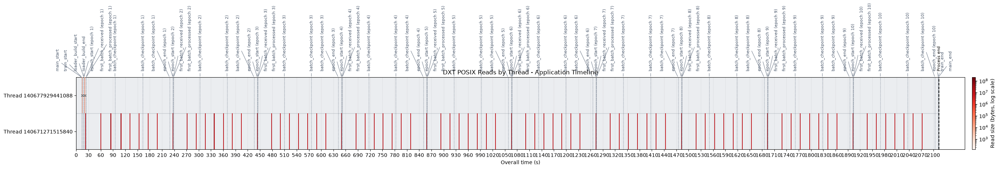

In [35]:
# ---------------------------------------------------------
# 1. Load and select application events
# ---------------------------------------------------------

LOG_PATH = Path('logs/root_stream_bim_2_shuffle_false_epochs_10_20261110_061713/logs/log.strategy_stream_bim_2_shuffle_false_batchsize_64_epochs_10.txt')

selected_event_names = {
    "main_start",
    "train_start",
    "loader_build_start",
    "loader_build_end",
    "epoch_start",
    "epoch_end",
    "first_batch_received",
    "first_batch_processed",
    "batch_checkpoint",
    "train_end",
    "main_end",
}

job = d["metadata"]["job"]

darshan_start_ns = (
    int(job["start_time_sec"]) * 1_000_000_000
    + int(job["start_time_nsec"])
)

runtime = job["run_time"]

events = []

with LOG_PATH.open("r", encoding="utf-8") as f:
    for line in f:
        if not line.startswith("TRACE_EVENT "):
            continue

        event = json.loads(line[len("TRACE_EVENT "):])

        if event["event"] not in selected_event_names:
            continue

        event["time_s"] = (
            int(event["unix_ns"]) - darshan_start_ns
        ) / 1_000_000_000

        events.append(event)

events.sort(key=lambda e: e["time_s"])

if not events:
    raise ValueError("No selected TRACE_EVENT records were found.")

if any(e["time_s"] < 0 or e["time_s"] > runtime for e in events):
    raise ValueError(
        "Application events fall outside the Darshan runtime. "
        "Check that both files belong to the same execution."
    )

print(f"Selected application events: {len(events)}")

for event in events:
    print(f"{event['time_s']:9.3f}s  {event['event']}")


# ---------------------------------------------------------
# 2. Prepare DXT read operations
# ---------------------------------------------------------

dataset_record = next(
    record for record in dxt_data
    if record["file_name"].endswith("mc_normalized_rntuple_10M_9.root")
)

reads = sorted(
    [row for row in dataset_record["rows"]
     if row["operation"] == "read"],
    key=lambda row: row["start_s"]
)

positive_lengths = [r["length"] for r in reads if r["length"] > 0]

norm = mcolors.LogNorm(
    vmin=min(positive_lengths),
    vmax=max(positive_lengths)
)

cmap = plt.get_cmap("Reds")

thread_ids = sorted({str(r["pthread_id"]) for r in reads})

thread_reads = {
    tid: [r for r in reads if str(r["pthread_id"]) == tid]
    for tid in thread_ids
}


# ---------------------------------------------------------
# 3. Build contiguous thread lanes
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(30, 6))

lane_height = 0.8

lane_bottoms = {
    tid: i * lane_height
    for i, tid in enumerate(thread_ids)
}

for tid in thread_ids:
    y0 = lane_bottoms[tid]

    ax.broken_barh(
        [(0, runtime)],
        (y0, lane_height),
        facecolors="#ebedf0",
        edgecolors="#c8ccd1",
        zorder=1
    )

    for row in thread_reads[tid]:
        start = row["start_s"]
        end = row["end_s"]
        length = row["length"]
        duration = end - start

        if length == 0:
            ax.plot(
                start,
                y0 + lane_height / 2,
                "x",
                color="gray",
                markersize=5,
                zorder=5
            )
            continue

        color = cmap(norm(length))

        if duration > 0:
            ax.broken_barh(
                [(start, duration)],
                (y0, lane_height),
                facecolors=color,
                edgecolors="none",
                zorder=3
            )

        ax.vlines(
            start,
            y0,
            y0 + lane_height,
            color=color,
            linewidth=1.2,
            zorder=4
        )


# ---------------------------------------------------------
# 4. Application event lines
# ---------------------------------------------------------

event_line_color = "#475569"

for event in events:
    ax.axvline(
        event["time_s"],
        color=event_line_color,
        linestyle=":",
        linewidth=1,
        alpha=0.8,
        zorder=6
    )


# ---------------------------------------------------------
# 5. Process end
# ---------------------------------------------------------

ax.axvline(
    runtime,
    color="black",
    linestyle="--",
    linewidth=1.4,
    zorder=7
)


# ---------------------------------------------------------
# 6. Axes
# ---------------------------------------------------------

ax.set_xlim(0, runtime * 1.03)
ax.set_ylim(0, lane_height * len(thread_ids))

tick_step = (
    5 if runtime <= 600
    else 30 if runtime <= 3600
    else 120
)

ax.set_xticks(range(0, int(runtime) + 1, tick_step))

ax.set_yticks([
    lane_bottoms[tid] + lane_height / 2
    for tid in thread_ids
])

ax.set_yticklabels([
    f"Thread {tid}"
    for tid in thread_ids
])

ax.set_xlabel("Overall time (s)")
ax.set_title("DXT POSIX Reads by Thread - Application Timeline")

ax.grid(axis="x", alpha=0.2)


# ---------------------------------------------------------
# 7. Read-size colorbar
# ---------------------------------------------------------

sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    fraction=0.012,
    pad=0.008
)

cbar.set_label("Read size (bytes, log scale)")


# ---------------------------------------------------------
# 8. Vertical event labels above the plot
# ---------------------------------------------------------

# Leave sufficient room above the timeline
fig.subplots_adjust(
    left=0.12,
    right=0.95,
    bottom=0.14,
    top=0.47
)

fig.canvas.draw()

# Group labels that would overlap horizontally
# using their actual display positions
event_groups = []
current_group = []

min_spacing_px = 22

for event in events:
    x_px = ax.transData.transform((event["time_s"], 0))[0]

    if current_group and x_px - current_group[-1][1] >= min_spacing_px:
        event_groups.append(current_group)
        current_group = []

    current_group.append((event, x_px))

if current_group:
    event_groups.append(current_group)

# Place rotated labels with small horizontal offsets
# while keeping event lines at their true timestamps
for group in event_groups:
    n = len(group)

    for i, (event, _) in enumerate(group):
        label = event["event"]

        if "epoch" in event:
            label += f" (epoch {event['epoch']})"

        offset_pt = (i - (n - 1) / 2) * 16

        ax.annotate(
            label,
            xy=(event["time_s"], 1.0),
            xycoords=("data", "axes fraction"),
            xytext=(offset_pt, 12),
            textcoords="offset points",
            rotation=90,
            ha="center",
            va="bottom",
            fontsize=8,
            color=event_line_color,
            annotation_clip=False,
            arrowprops=dict(
                arrowstyle="-",
                color=event_line_color,
                linewidth=0.6
            )
        )

# Label the process end directly
ax.annotate(
    "Process end",
    xy=(runtime, 1.0),
    xycoords=("data", "axes fraction"),
    xytext=(0, 12),
    textcoords="offset points",
    rotation=90,
    ha="center",
    va="bottom",
    fontsize=8,
    color="black",
    annotation_clip=False
)


# ---------------------------------------------------------
# 9. Save
# ---------------------------------------------------------

plt.savefig(
    "dxt_threads_with_vertical_events10.png",
    dpi=180,
    bbox_inches="tight"
)

plt.savefig(
    "dxt_threads_with_vertical_events10.svg",
    bbox_inches="tight"
)

plt.show()